In [1]:
%pip install pandas matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("penguins.csv")

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())
display(df.dtypes)

Dataset shape: (344, 8)
Columns: ['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex', 'year']


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


species                  str
island                   str
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                      str
year                   int64
dtype: object

In [2]:
import os
print(os.getcwd())
print(os.listdir())

/Users/z.young
['truck.csv', 'module2_lab2.ipynb', '.config', 'Music', 'store_customers.csv', '.copilot', 'messy_sales.csv', '.anyconnect', 'allbacks.csv', '.DS_Store', 'Module 7 Lab 3.ipynb', 'store_orders.csv', '.vscode-shared', '.CFUserTextEncoding', 'Module 7 Lab 1.ipynb', '.xonshrc', 'custdata.tsv', 'anaconda_projects', '.zshrc', '.ServiceHub', '.templateengine', '.local', 'Pictures', 'Module 4 Lab 3.ipynb', '.nuget', '.zsh_history', 'Assignment', '.ipython', 'Desktop', 'Module 8 Lab 1.ipynb', 'Library', '.matplotlib', 'tips.csv', 'module5_lab2.ipynb', 'ratings.tsv', 'usarrests.csv', 'Module 7 Lab 2.ipynb', 'miniforge3', 'Module 6 Lab 1.ipynb', 'chickwts.csv', 'Module 6 Lab 3.ipynb', 'module4_lab1.ipynb', 'Public', 'module3_lab.ipynb', '.tcshrc', 'module3_lab2.ipynb', '.cisco', 'store.db', '.anaconda', 'Movies', '.dotnet', 'Applications', 'museum_visitors.csv', '.jfreereport', 'module1_lab3.ipynb', '.Trash', 'analytics_db.db', 'sales_clean.csv', '.ipynb_checkpoints', '.jupyter', '

In [3]:
print("Dataset shape:")
print(df.shape)

print("\nMissing values per column:")
print(df.isnull().sum())

print("\nPenguin counts by species:")
print(df["species"].value_counts())

Dataset shape:
(344, 8)

Missing values per column:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

Penguin counts by species:
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


I calculated the dataset dimensions, missing-value counts, and
number of penguins in each species using pandas before asking AI
to analyze the dataset.

These results are my ground truth for verifying the AI-generated
analysis.

## Prompt Log

### Initial Prompt

You are helping with exploratory data analysis.

My CSV file is called penguins.csv. It contains 344 rows and 8 columns.

The columns and data types are:

species: object

island: object

bill_length_mm: float64

bill_depth_mm: float64

flipper_length_mm: float64

body_mass_g: float64

sex: object

year: int64

Write Python code using pandas, matplotlib, and seaborn to:

Summarize missing data in every column.

Compare mean flipper length in millimeters across the three penguin species.

Produce at least one clearly labeled chart showing the comparison.

Include comments explaining each step.

Handle missing values appropriately and explain how missing values affect the group means.

Do not invent results. Make sure the code can run in Google Colab after penguins.csv has been loaded into a pandas DataFrame named df.

Return the code and briefly explain what it does.

Missing Data Summary


,Missing Count,Missing Percent
species,0,0.00
island,0,0.00
bill_length_mm,2,0.58
bill_depth_mm,2,0.58
flipper_length_mm,2,0.58
body_mass_g,2,0.58
sex,11,3.20
year,0,0.00


Mean Flipper Length by Species (mm)


species
Adelie       189.953642
Chinstrap    195.823529
Gentoo       217.186992
Name: flipper_length_mm, dtype: float64

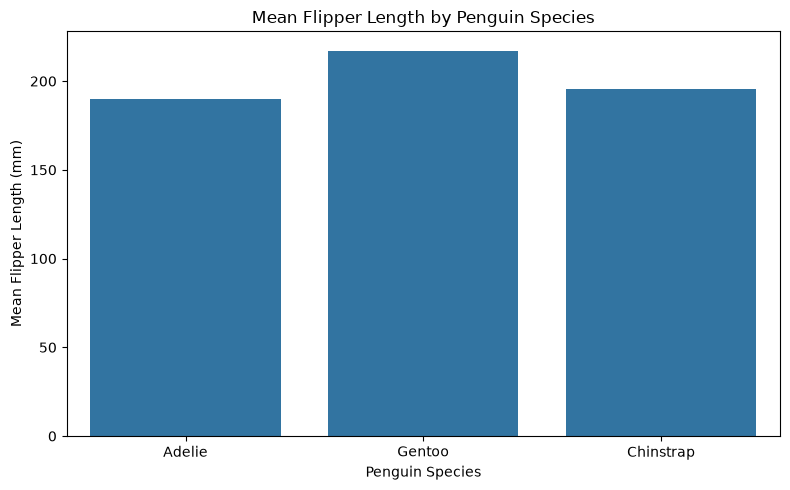

In [4]:

# 1. Summarize missing values
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percent": (df.isnull().mean() * 100).round(2)
})

print("Missing Data Summary")
display(missing_summary)

# 2. Compare mean flipper length by species
species_flipper_means = (
    df.groupby("species")["flipper_length_mm"]
      .mean()
      .sort_values()
)

print("Mean Flipper Length by Species (mm)")
display(species_flipper_means)

# 3. Create a labeled chart
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="species",
    y="flipper_length_mm",
    errorbar=None
)

plt.title("Mean Flipper Length by Penguin Species")
plt.xlabel("Penguin Species")
plt.ylabel("Mean Flipper Length (mm)")
plt.tight_layout()
plt.show()

In [5]:
verified_means = df.groupby("species")["flipper_length_mm"].mean()

print("My independently calculated means:")
print(verified_means.round(2))

My independently calculated means:
species
Adelie       189.95
Chinstrap    195.82
Gentoo       217.19
Name: flipper_length_mm, dtype: float64


I independently calculated the mean flipper length for each species
using pandas groupby() and mean().

My results were:

- Adelie: 189.95 mm
- Chinstrap: 195.82 mm
- Gentoo: 217.19 mm

I compared these values with the AI's results.

Verifycation outcome: Match

Please extend the penguin EDA by comparing body mass in grams across the three species. Create a clearly labeled chart, handle missing values appropriately, and explain one useful observation from the results. Provide runnable Python code for ChatGPT using my existing DataFrame named df.

Mean Body Mass by Species (grams):


species
Adelie       3700.7
Chinstrap    3733.1
Gentoo       5076.0
Name: body_mass_g, dtype: float64

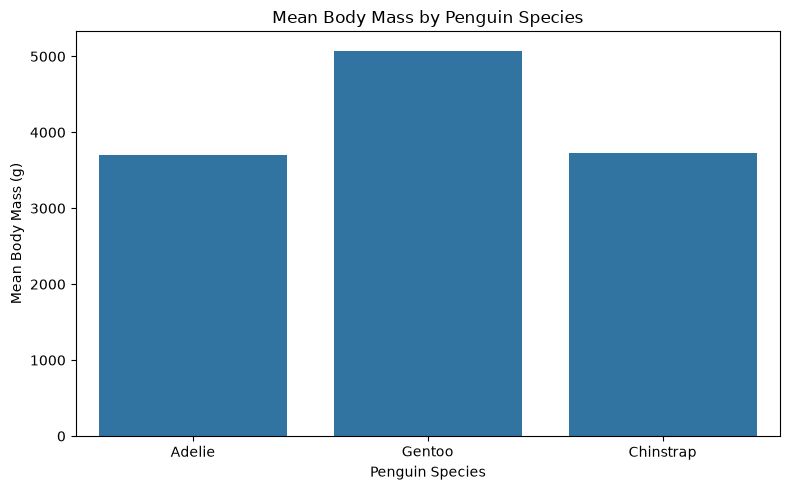

In [7]:

# Compare mean body mass across species
body_mass_means = df.groupby("species")["body_mass_g"].mean()

print("Mean Body Mass by Species (grams):")
display(body_mass_means.round(1))

# Plot the results
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="species",
    y="body_mass_g",
    errorbar=None
)

plt.title("Mean Body Mass by Penguin Species")
plt.xlabel("Penguin Species")
plt.ylabel("Mean Body Mass (g)")
plt.tight_layout()
plt.show()


Judgment: I kept this suggestion because the body-mass chart provides an additional comparison between the species. It shows that Gentoo penguins have a substantially higher average body mass than the other two species.

Species counts by island:


species,Adelie,Chinstrap,Gentoo
island,,,
Biscoe,44,0,124
Dream,56,68,0
Torgersen,52,0,0


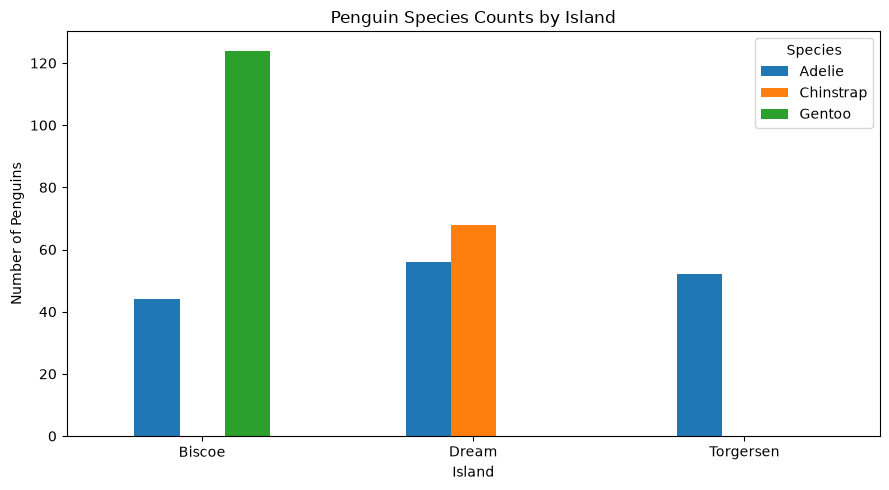

In [8]:

# My own investigation: species counts by island
island_species_counts = pd.crosstab(df["island"], df["species"])

print("Species counts by island:")
display(island_species_counts)

# Create my own chart
island_species_counts.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Penguin Species Counts by Island")
plt.xlabel("Island")
plt.ylabel("Number of Penguins")
plt.xticks(rotation=0)
plt.legend(title="Species")
plt.tight_layout()
plt.show()

My own investigation found that penguin species are distributed
differently across the three islands. The dataset contains 68
Chinstrap penguins on Dream Island and 124 Gentoo penguins on
Biscoe Island, with zero recorded for those species on the other
islands shown in the table.

I identified this pattern by producing my own species-by-island
count table and chart.

## Privacy Reflection

I would never paste confidential police reports containing names, home addresses, witness statements, or other identifying information into a public AI tool. Instead, I would remove identifying information, aggregate the data when appropriate, and use an approved internal tool if the information still requires protection. I would follow the organization's data-handling policies before sharing any information with an AI system.